> **Modelo ampliado disponível:** veja `09_treino_ampliado_spherex.ipynb`. Os 720 exemplos descritos aqui são a versão inicial; o comando padrão agora usa o modelo ampliado ativo.

# Treinamento observado: SPHEREx + Gaia

**Este treinamento não usa fontes injetadas nem artefatos fabricados.** Os pixels
vêm dos FITS observados pelo SPHEREx; o Gaia fornece posições e identificações
catalogadas para associar fontes. As consultas são feitas com Astroquery.

O modelo compara **fontes observadas** com **contaminação instrumental indicada
nos FITS**. Isso não é um classificador de asteroides contra estrelas. A procura
de movimento continua na associação entre épocas.

- SPHEREx: `astroquery.ipac.irsa.Irsa.query_sia`.
- Gaia: `astroquery.gaia.Gaia.launch_job`, tabela `gaiadr3.gaia_source`.
- Os oito FITS já baixados são reutilizados; seus IDs são verificados contra a
  consulta ao arquivo e seus hashes ficam no relatório.

In [1]:
import json
from pathlib import Path

from astropy.table import Table
from IPython.display import JSON, Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "outputs/observed"
r = json.loads((OUT / "observed_report.json").read_text())
ranking = json.loads((OUT / "candidate_ranking.json").read_text())
print("Fontes no catálogo Gaia consultado:", r["n_gaia_catalog_sources"])
print("Imagens retornadas pela consulta SPHEREx:", r["n_spherex_archive_rows"])
print("Exemplos observados usados:", r["n_observed_samples"])
print("Observações associadas ao Gaia:", r["n_positive_samples"])
print("Fontes Gaia distintas:", r["unique_gaia_source_ids"])
print("Exemplos com flags instrumentais:", r["n_flagged_contamination_samples"])
print("Exemplos artificiais:", r["artificial_samples"])

Fontes no catálogo Gaia consultado: 451
Imagens retornadas pela consulta SPHEREx: 237
Exemplos observados usados: 720
Observações associadas ao Gaia: 215
Fontes Gaia distintas: 46
Exemplos com flags instrumentais: 505
Exemplos artificiais: 0


## Exemplos reais e origem dos rótulos

**Fonte observada:** detecção SPHEREx próxima de uma fonte Gaia isolada, com
núcleo sem flags de defeito. O movimento próprio do Gaia é propagado até a data
da observação antes da associação.

**Contaminação instrumental:** pico observado com flag de transiente, defeito,
outlier, crosstalk, ghost ou outra contaminação selecionada, sem contraparte Gaia
próxima. São rótulos de catálogo/qualidade, não revisão manual de eventos.

**Ausência no Gaia não cria um rótulo negativo.** Fontes desconhecidas sem
indicação instrumental permanecem sem rótulo. O arquivo de treino registra a
identificação Gaia ou o valor do flag de cada exemplo.

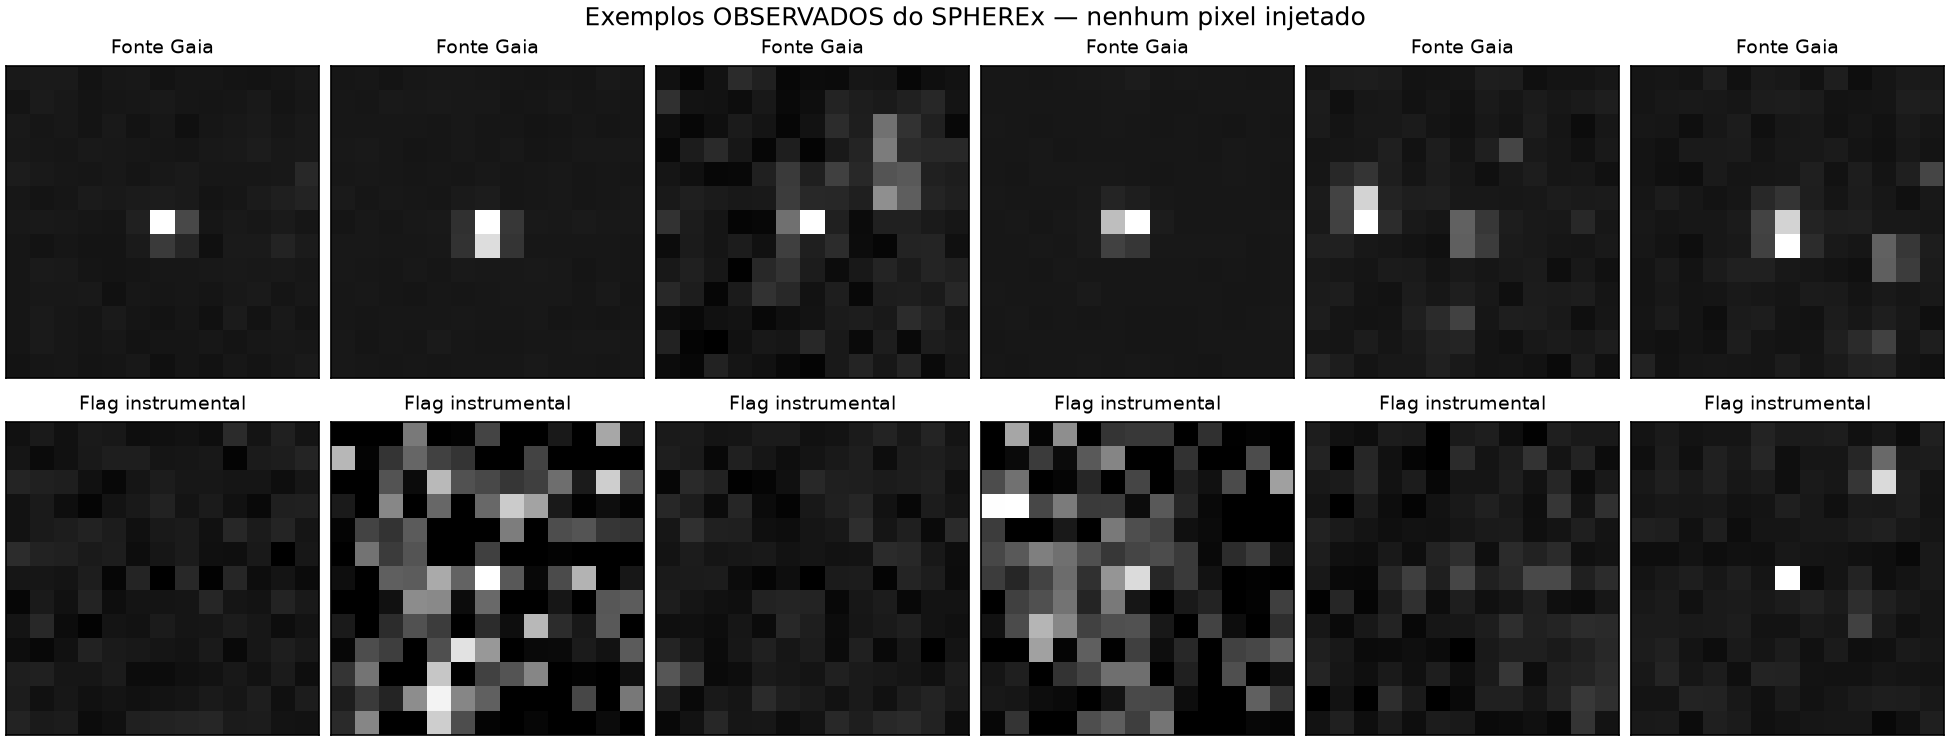

epoca,rotulo,origem,gaia_id,flags
str1,str10,str40,str18,str7
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610634299545189120,2097152
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610588601093222272,2097152
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610585062040163968,2097152
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610588665517018624,2097152
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610589043474552448,2097152
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610589047769817472,2097152
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610681956502180480,2097152
0,fonte Gaia,Gaia DR3 matched observed SPHEREx source,610588390639531008,2097152


In [2]:
import csv

display(Image(filename=str(OUT / "observed_examples.png")))

with (OUT / "observed_training_samples.csv").open() as handle:
    samples = list(csv.DictReader(handle))
rows = [
    {
        "epoca": s["epoch"],
        "rotulo": "fonte Gaia" if s["label"] == "1" else "contaminação",
        "origem": s["label_origin"],
        "gaia_id": s["gaia_source_id"],
        "flags": s["instrument_flags"],
    }
    for s in samples[:8]
]
display(Table(rows=rows))

## Treino e avaliação

O XGBoost usa características dos pixels da exposição nativa, tanto no treino
quanto na avaliação dos candidatos. Não transfere silenciosamente características
de imagens nativas para resíduos de subtração.

As identificações Gaia repetidas ficam no mesmo grupo. O mesmo acontece com
coordenadas de defeitos do detector: a mesma identidade não entra nos conjuntos
de treino e teste. Flags, IDs e rótulos não entram nas características do modelo.
O limite de treinamento continua sendo dois minutos.

As métricas abaixo se referem a **fonte observada contra contaminação sinalizada**.
Não são uma taxa de acerto de asteroides ou de eventos verdadeiros em imagens de
diferença.

In [3]:
m = r["training"]
print("Estado:", m["status"])
print(f"Tempo total do processo: {m['wall_seconds']:.2f} s")
print("Exemplos de treino / validação / teste:", m["n_train"], m["n_validation"], m["n_test"])
cm = m["confusion_matrix"]
correct = cm[0][0] + cm[1][1]
total = sum(map(sum, cm))
print(f"Acertos no conjunto observado reservado: {correct}/{total}")
print("Matriz: linhas = classe observada; colunas = classe prevista")
display(Table(rows=cm, names=["previsto_instrumental", "previsto_fonte"]))

Estado: complete
Tempo total do processo: 1.71 s
Exemplos de treino / validação / teste: 444 148 128
Acertos no conjunto observado reservado: 123/128
Matriz: linhas = classe observada; colunas = classe prevista


previsto_instrumental,previsto_fonte
int64,int64
99,5
0,24


## Ranking e movimento refeitos

O ranking abaixo usa o novo modelo treinado em observações. “Fonte candidata”
significa que o ponto na imagem nativa se parece com uma fonte observada.
Uma estrela estacionária também pode receber essa classificação; a ligação de
posições e velocidades é uma etapa separada.

ordem,id,prioridade,classe,Gaia,epocas
int64,int64,float64,str15,str18,int64
1,38,98.4,fonte_candidata,,5
2,81,98.1,fonte_candidata,,5
3,199,98.1,fonte_candidata,,5
4,11,98.0,fonte_candidata,,5
5,61,98.0,fonte_candidata,610589357007462528,7
6,120,98.0,fonte_candidata,,4
7,150,98.0,fonte_candidata,,6
8,24,98.0,fonte_candidata,,5
9,118,97.9,fonte_candidata,,6


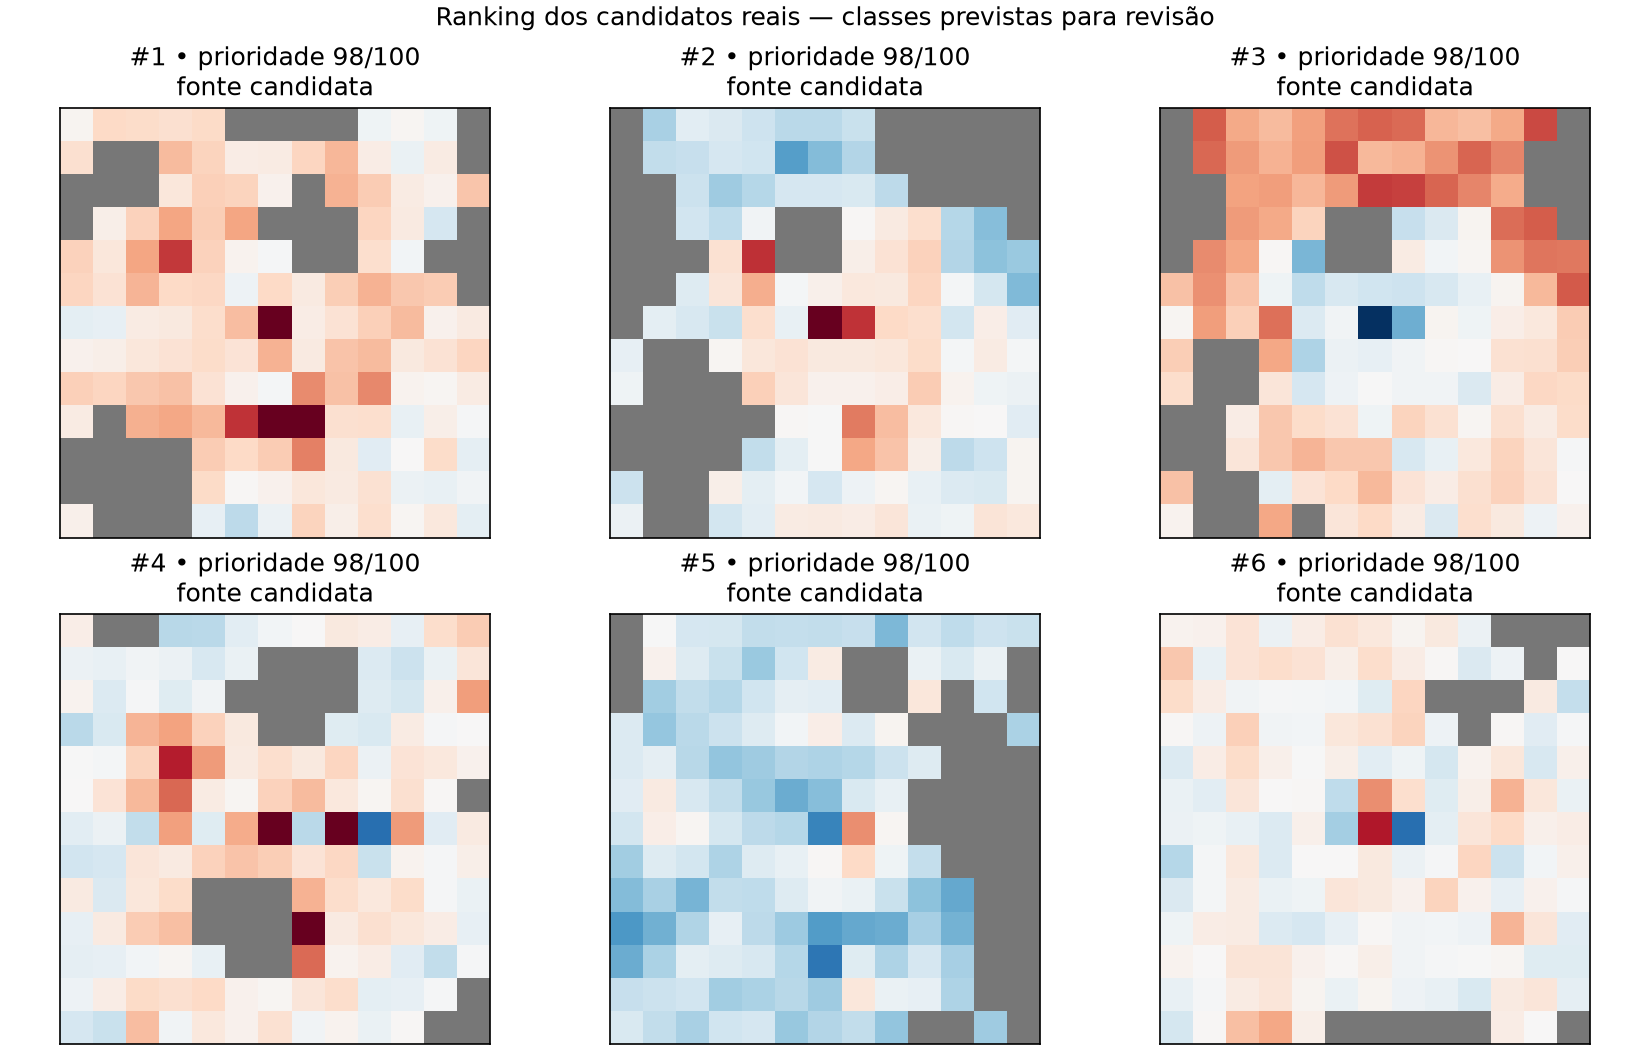

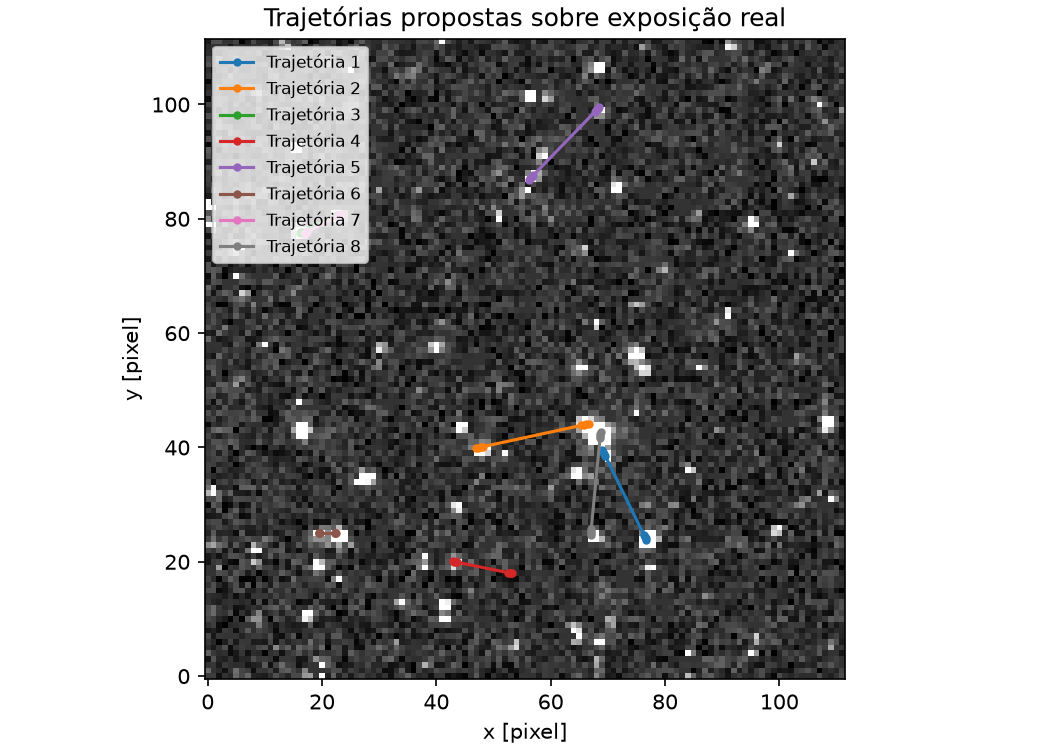

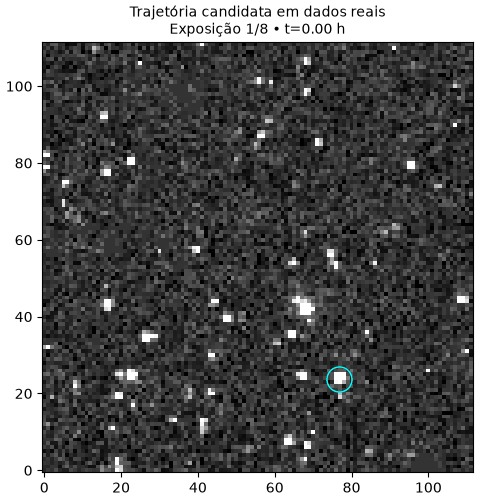

In [4]:
display(
    Table(
        rows=[
            {
                "ordem": c["rank"],
                "id": c["candidate_id"],
                "prioridade": round(c["priority_score"], 1),
                "classe": c["predicted_class"],
                "Gaia": c.get("gaia_source_id", ""),
                "epocas": c["motion_support_epochs"],
            }
            for c in ranking[:12]
        ]
    )
)
display(Image(filename=str(OUT / "ranking.png")))
display(Image(filename=str(OUT / "tracks.png")))
if (OUT / "candidate_blink.gif").exists():
    display(Image(filename=str(OUT / "candidate_blink.gif")))

## Executar

```bash
uv run --extra ml spherex-tracking sprints
```

Para reutilizar o modelo observado sem treinar novamente:
```bash
uv run --extra ml spherex-tracking sprints --reuse-training
```

Consultas e catálogos ficam em `data/catalogs/`; os exemplos auditáveis, modelo,
ranking e animação ficam em `outputs/observed/`. O experimento sintético antigo
exige a opção explícita `--synthetic-controls`.

[Documentação Astroquery IRSA](https://astroquery.readthedocs.io/en/latest/ipac/irsa/irsa.html)
· [Documentação Astroquery Gaia](https://astroquery.readthedocs.io/en/latest/gaia/gaia.html).

In [5]:
display(JSON(r))

<IPython.core.display.JSON object>